# Research Notebook 1 — Chemical Gas Identification, Concentration Estimation & Sensor-Drift Generalization

**Research theme:** Environmental sensing / electronic noses / machine learning under distribution shift  
**Dataset:** *Gas Sensor Array Drift at Different Concentrations* (UCI; 13,910 measurements, 128 engineered features, six gases)  
**Project type:** Reproducible experimental study; classification + regression + unsupervised pattern discovery

## Research question
How well do classical ML models identify the gas and estimate its concentration when test measurements come from a later acquisition batch than the measurements used for training?

### Research contributions in this notebook
1. A strict **later-batch holdout** (train on batches 1–6, final test on batch 10) to study drift/generalization rather than only a random split.
2. A transparent in-period validation comparison across Logistic Regression, Decision Tree, KNN, RBF-SVM and Random Forest.
3. Continuous concentration estimation, evaluated in the original ppmv unit and against a trivial baseline.
4. Unsupervised PCA/K-Means exploration with silhouette score and adjusted Rand index (ARI), where labels are used for evaluation only.

**Important:** Batch 10 is not used to choose models or tune hyperparameters. Since the source describes batches by month, this is a later-batch test, not proof of deployment performance on every future sensor installation.

## Dataset provenance and citation

- **Official source:** [UCI Machine Learning Repository — Gas Sensor Array Drift at Different Concentrations](https://archive.ics.uci.edu/dataset/270/gas+sensor+array+drift+dataset+at+different+concentrations)
- **DOI:** [10.24432/C5MK6M](https://doi.org/10.24432/C5MK6M)
- **Creator / recommended dataset citation:** Vergara, A. (2012). *Gas Sensor Array Drift at Different Concentrations*. UCI Machine Learning Repository.
- **Local data archive used here:** `datasets/gas_sensor_drift_source.zip`; it contains the ten `batch*.dat` files supplied with this project bundle.
- **Encoding:** each row contains gas class ID, concentration (ppmv), and 128 indexed sensor-derived features. The six documented class IDs are 1 Ethanol, 2 Ethylene, 3 Ammonia, 4 Acetaldehyde, 5 Acetone, and 6 Toluene.

### Hypotheses
- **H1:** Random/in-period validation scores may overestimate the performance on a later acquisition batch.
- **H2:** Concentration estimates may be less stable across batches than within a mixed random split.
- **H3:** Unsupervised clusters will capture some—but not necessarily all—of the gas-class structure.

### Evaluation plan
- Classification: accuracy, macro precision/recall/F1, per-class report and confusion matrix.
- Concentration regression: MAE, RMSE and R² on original ppmv scale; compare with a median dummy regressor.
- Clustering: silhouette score and ARI. ARI is a post-hoc external measure; it is not used to fit K-Means.

In [1]:
from pathlib import Path
import zipfile, re, warnings
import numpy as np
import pandas as pd
from threadpoolctl import threadpool_limits
threadpool_limits(limits=1)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 180)
pd.set_option('display.max_colwidth', 60)
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay, mean_absolute_error,
                             mean_squared_error, r2_score, silhouette_score, adjusted_rand_score)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.base import clone

SEED = 42
np.random.seed(SEED)
GAS_NAMES = {1:'Ethanol', 2:'Ethylene', 3:'Ammonia', 4:'Acetaldehyde', 5:'Acetone', 6:'Toluene'}

def find_project_file(filename):
    candidates = [Path.cwd()/"datasets"/filename, Path.cwd()/filename,
                  Path.cwd().parent/"datasets"/filename, Path('/content')/"datasets"/filename]
    for p in candidates:
        if p.exists(): return p
    raise FileNotFoundError(f"Could not find {filename}. Keep the datasets/ folder beside this notebook. Checked: {candidates}")

source_zip = find_project_file('gas_sensor_drift_source.zip')
print('Source archive: datasets/gas_sensor_drift_source.zip')

Source archive: datasets/gas_sensor_drift_source.zip


In [2]:
# Parse the original libsvm-like rows directly from the supplied archive.
rows = []
with zipfile.ZipFile(source_zip) as zf:
    data_files = sorted([n for n in zf.namelist() if re.fullmatch(r'batch\d+\.dat', Path(n).name)],
                        key=lambda n: int(re.search(r'batch(\d+)', Path(n).name).group(1)))
    for member in data_files:
        batch_id = int(re.search(r'batch(\d+)', Path(member).name).group(1))
        with zf.open(member) as f:
            for raw in f:
                line = raw.decode('utf-8').strip()
                if not line: continue
                class_part, rest = line.split(';', 1)
                tokens = rest.split()
                concentration = float(tokens[0])
                values = np.zeros(128, dtype=np.float32)
                for token in tokens[1:]:
                    idx, val = token.split(':', 1)
                    values[int(idx)-1] = float(val)
                rows.append((batch_id, int(class_part), concentration, *values))

feature_cols = [f'sensor_feature_{i:03d}' for i in range(1, 129)]
columns = ['batch', 'gas_id', 'concentration_ppmv'] + feature_cols
data = pd.DataFrame(rows, columns=columns)
data['gas_name'] = data['gas_id'].map(GAS_NAMES)
print(f'Loaded {len(data):,} measurements across {data.batch.nunique()} acquisition batches.')
print(f'Feature matrix: {data.shape[0]:,} rows × {len(feature_cols)} sensor-derived features.')
display(data[['batch','gas_id','gas_name','concentration_ppmv']].head())
display(data.groupby('batch').agg(measurements=('gas_id','size'), gases=('gas_id','nunique'),
                                  concentration_min=('concentration_ppmv','min'),
                                  concentration_max=('concentration_ppmv','max')))
print('Missing cells in sensor features:', int(data[feature_cols].isna().sum().sum()))

Loaded 13,910 measurements across 10 acquisition batches.
Feature matrix: 13,910 rows × 128 sensor-derived features.


,batch,gas_id,gas_name,concentration_ppmv
0,1,1,Ethanol,10.0
1,1,1,Ethanol,20.0
2,1,1,Ethanol,30.0
3,1,1,Ethanol,40.0
4,1,1,Ethanol,50.0


,measurements,gases,concentration_min,concentration_max
batch,,,,
1,445,6,5.0,1000.0
2,1244,6,10.0,600.0
3,1586,5,10.0,300.0
4,161,5,50.0,250.0
5,197,5,50.0,500.0
6,2300,6,10.0,250.0
7,3613,6,1.0,300.0
8,294,6,10.0,500.0
9,470,6,10.0,120.0


Missing cells in sensor features: 0


## 1. Exploratory data analysis

Batch-wise class balance is shown first because acquisition batch is a core part of the research question. A random row-wise split can mix measurements from the same acquisition periods across train and test, so the final experiment instead holds out batch 10.

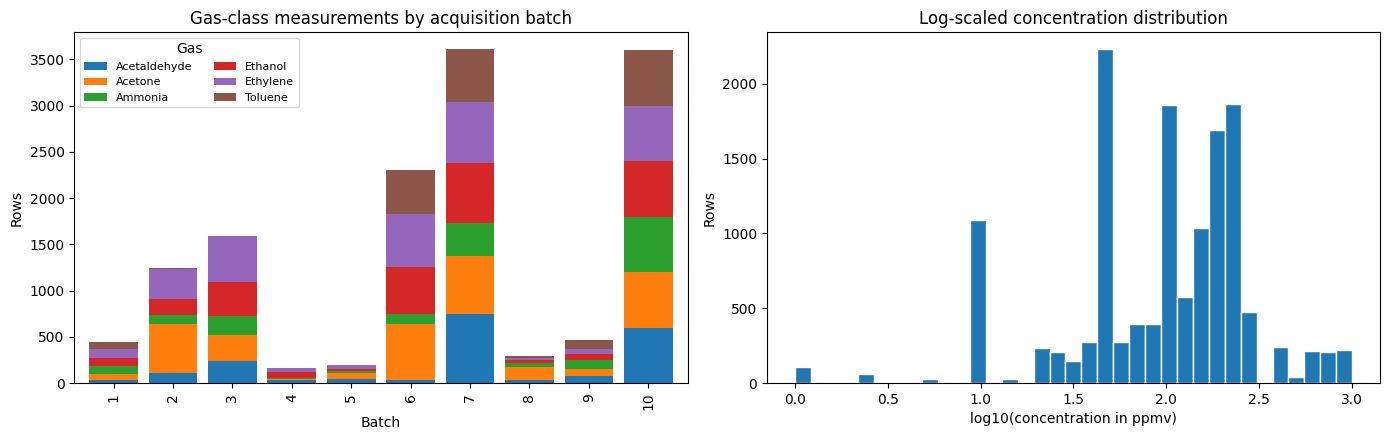

,count,min,median,max
gas_name,,,,
Acetaldehyde,1936,2.5,100.0,300.0
Acetone,3009,10.0,175.0,1000.0
Ammonia,1641,2.5,230.0,1000.0
Ethanol,2565,2.5,100.0,600.0
Ethylene,2926,2.5,100.0,300.0
Toluene,1833,1.0,50.0,230.0


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
class_counts = data.groupby(['batch','gas_name']).size().unstack(fill_value=0)
class_counts.plot(kind='bar', stacked=True, ax=axes[0], width=0.82)
axes[0].set_title('Gas-class measurements by acquisition batch')
axes[0].set_xlabel('Batch'); axes[0].set_ylabel('Rows'); axes[0].legend(title='Gas', fontsize=8, ncol=2)
axes[1].hist(np.log10(data['concentration_ppmv'].clip(lower=0.1)), bins=35, edgecolor='white')
axes[1].set_title('Log-scaled concentration distribution')
axes[1].set_xlabel('log10(concentration in ppmv)'); axes[1].set_ylabel('Rows')
plt.tight_layout(); plt.show()

display(data.groupby('gas_name')['concentration_ppmv'].agg(['count','min','median','max']).round(2))

## 2. Classification: choose a model without using the final batch

**Validation design:** batches 1–6 only; random stratified split inside these earlier batches for model selection. To keep runtime predictable, the classifier experiment balances up to 350 earlier-batch rows per gas class (about 2,100 samples); the final selected classifier is fit on that same capped pool. **Final temporal-like test:** all 3,600 measurements from batch 10. Batch 7–9 are intentionally not used in the final test so the holdout remains a later acquisition batch with all six documented gas classes.

In [4]:
train_period = data[data['batch'].between(1, 6)].copy()
final_test = data[data['batch'].eq(10)].copy()
# Cap each class at 350 rows for model-selection speed while preserving all six gases.
# The full early-batch pool remains available for the separate regression experiment.
model_pool = pd.concat([g.sample(n=min(350, len(g)), random_state=SEED)
                        for _, g in train_period.groupby('gas_id')], ignore_index=True)
X_all = model_pool[feature_cols]
y_all = model_pool['gas_id']
print(f'Full batches 1–6 pool: {len(train_period):,} rows; model-selection/final classifier pool: {len(model_pool):,} rows.')
display(model_pool['gas_name'].value_counts().rename('training_samples').to_frame())
X_tr, X_val, y_tr, y_val = train_test_split(
    X_all, y_all, test_size=0.25, random_state=SEED, stratify=y_all
)

model_specs = {
    'Logistic Regression': Pipeline([('scale', StandardScaler()), ('model', LogisticRegression(max_iter=500, tol=1e-3, class_weight='balanced'))]),
    'Decision Tree': Pipeline([('model', DecisionTreeClassifier(max_depth=20, min_samples_leaf=2, class_weight='balanced', random_state=SEED))]),
    'KNN (k=7)': Pipeline([('scale', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=7, weights='distance'))]),
    'Linear SVM': Pipeline([('scale', StandardScaler()), ('model', LinearSVC(C=0.5, class_weight='balanced', random_state=SEED, max_iter=1500, tol=1e-3))]),
    'Random Forest': Pipeline([('model', RandomForestClassifier(n_estimators=60, min_samples_leaf=2, class_weight='balanced_subsample', random_state=SEED, n_jobs=2))]),
}
validation_rows = []
fitted_validation = {}
for name, model in model_specs.items():
    model.fit(X_tr, y_tr)
    pred = model.predict(X_val)
    fitted_validation[name] = model
    validation_rows.append({'model': name, 'accuracy': accuracy_score(y_val, pred),
                            'macro_precision': precision_score(y_val, pred, average='macro', zero_division=0),
                            'macro_recall': recall_score(y_val, pred, average='macro', zero_division=0),
                            'macro_F1': f1_score(y_val, pred, average='macro', zero_division=0)})
validation_results = pd.DataFrame(validation_rows).sort_values('macro_F1', ascending=False).reset_index(drop=True)
display(validation_results.round(4))
best_name = validation_results.loc[0, 'model']
print('Selected using batches 1–6 validation only:', best_name)

Full batches 1–6 pool: 5,933 rows; model-selection/final classifier pool: 2,100 rows.


,training_samples
gas_name,
Ethanol,350
Ethylene,350
Ammonia,350
Acetaldehyde,350
Acetone,350
Toluene,350


,model,accuracy,macro_precision,macro_recall,macro_F1
0,Linear SVM,0.9867,0.9868,0.9867,0.9867
1,Logistic Regression,0.9867,0.9867,0.9867,0.9867
2,KNN (k=7),0.9810,0.9811,0.9810,0.9809
3,Random Forest,0.9771,0.9775,0.9772,0.9772
4,Decision Tree,0.9543,0.9547,0.9543,0.9543


Selected using batches 1–6 validation only: Linear SVM


,test_batch,test_rows,accuracy,macro_precision,macro_recall,macro_F1
0,10,3600,0.63,0.5535,0.63,0.5739


              precision    recall  f1-score   support

     Ethanol      0.669     0.778     0.720       600
    Ethylene      0.667     0.908     0.769       600
     Ammonia      0.698     0.547     0.613       600
Acetaldehyde      0.000     0.000     0.000       600
     Acetone      0.811     0.645     0.719       600
     Toluene      0.475     0.902     0.623       600

    accuracy                          0.630      3600
   macro avg      0.553     0.630     0.574      3600
weighted avg      0.553     0.630     0.574      3600



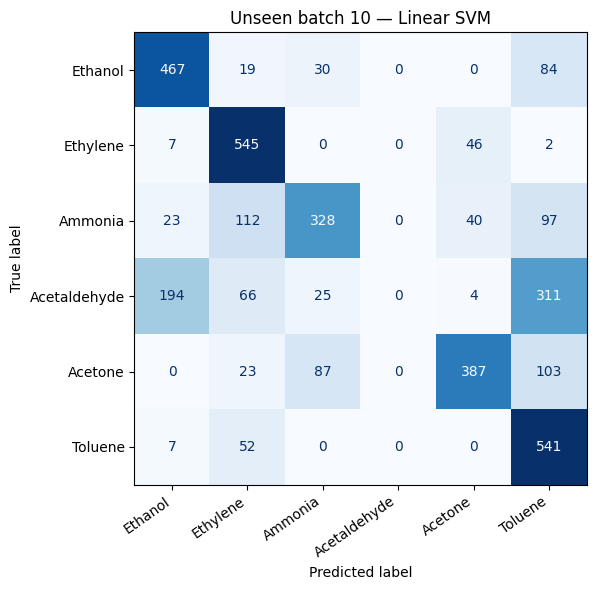

Majority-class baseline accuracy on batch 10: 0.167


In [5]:
# Refit the chosen model on every earlier batch, then evaluate once on unseen batch 10.
best_pipeline = clone(model_specs[best_name])
best_pipeline.fit(X_all, y_all)
X_test = final_test[feature_cols]
y_test = final_test['gas_id']
pred_test = best_pipeline.predict(X_test)
final_classification_metrics = {
    'test_batch': 10,
    'test_rows': len(final_test),
    'accuracy': accuracy_score(y_test, pred_test),
    'macro_precision': precision_score(y_test, pred_test, average='macro', zero_division=0),
    'macro_recall': recall_score(y_test, pred_test, average='macro', zero_division=0),
    'macro_F1': f1_score(y_test, pred_test, average='macro', zero_division=0),
}
display(pd.DataFrame([final_classification_metrics]).round(4))
print(classification_report(y_test, pred_test, labels=list(GAS_NAMES),
                            target_names=[GAS_NAMES[i] for i in GAS_NAMES], zero_division=0, digits=3))
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, labels=list(GAS_NAMES),
    display_labels=[GAS_NAMES[i] for i in GAS_NAMES], normalize=None, cmap='Blues', ax=ax, colorbar=False)
ax.set_title(f'Unseen batch 10 — {best_name}')
plt.xticks(rotation=35, ha='right'); plt.tight_layout(); plt.show()

# A chance / majority baseline adds context to the chosen model's later-batch result.
dummy = DummyClassifier(strategy='most_frequent').fit(X_all, y_all)
dummy_pred = dummy.predict(X_test)
print(f"Majority-class baseline accuracy on batch 10: {accuracy_score(y_test, dummy_pred):.3f}")

## 3. Concentration estimation (regression)

The target is the recorded concentration in ppmv. Concentrations are strongly right-skewed, so the estimator fits the logarithm of concentration and converts predictions back to ppmv before scoring. Gas identity is **not** passed as a feature; the model uses sensor-derived measurements only. Results can be much harder on the later batch, and this is an exploratory estimate rather than a calibrated instrument replacement.

Regression training rows: 3,000; final test rows: 3,600.


,model,MAE_ppmv,RMSE_ppmv,R2
0,Random Forest (log-target),146.740,231.458,0.298
1,Median baseline,186.722,310.204,-0.261


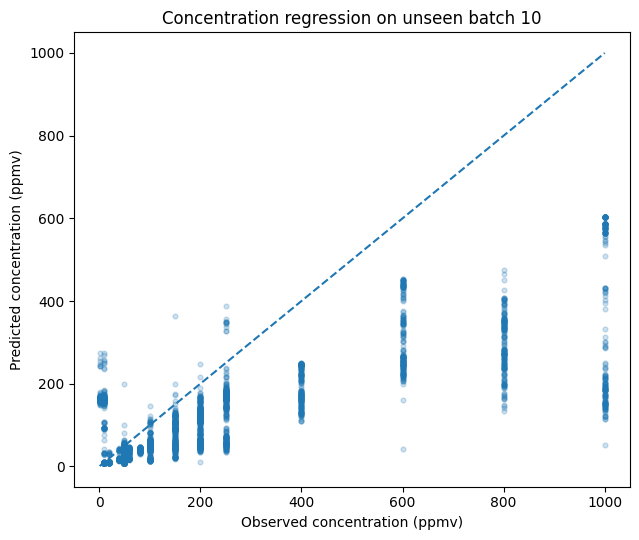

Interpret RMSE and R² alongside the median baseline; absolute ppmv errors are scale-dependent.


In [6]:
regressor = TransformedTargetRegressor(
    regressor=Pipeline([('scale', StandardScaler()),
        ('model', RandomForestRegressor(n_estimators=30, max_depth=15, min_samples_leaf=2,
                                        random_state=SEED, n_jobs=1))]),
    func=np.log10, inverse_func=lambda a: np.power(10.0, a)
)
reg_pool = train_period.sample(n=min(3000, len(train_period)), random_state=SEED)
print(f'Regression training rows: {len(reg_pool):,}; final test rows: {len(final_test):,}.')
regressor.fit(reg_pool[feature_cols], reg_pool['concentration_ppmv'])
conc_pred = regressor.predict(X_test)
rmse = float(np.sqrt(mean_squared_error(final_test['concentration_ppmv'], conc_pred)))
reg_metrics = pd.DataFrame([{
    'model':'Random Forest (log-target)', 'MAE_ppmv': mean_absolute_error(final_test['concentration_ppmv'], conc_pred),
    'RMSE_ppmv': rmse, 'R2': r2_score(final_test['concentration_ppmv'], conc_pred)
}])
dummy_reg = DummyRegressor(strategy='median').fit(reg_pool[feature_cols], reg_pool['concentration_ppmv'])
dummy_conc_pred = dummy_reg.predict(X_test)
reg_metrics.loc[len(reg_metrics)] = ['Median baseline', mean_absolute_error(final_test['concentration_ppmv'], dummy_conc_pred),
                                     np.sqrt(mean_squared_error(final_test['concentration_ppmv'], dummy_conc_pred)),
                                     r2_score(final_test['concentration_ppmv'], dummy_conc_pred)]
display(reg_metrics.round(3))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(final_test['concentration_ppmv'], conc_pred, alpha=0.22, s=12)
lims = [max(0, final_test['concentration_ppmv'].min()), final_test['concentration_ppmv'].max()]
ax.plot(lims, lims, linestyle='--', linewidth=1.5)
ax.set_xlabel('Observed concentration (ppmv)'); ax.set_ylabel('Predicted concentration (ppmv)')
ax.set_title('Concentration regression on unseen batch 10')
plt.tight_layout(); plt.show()
print('Interpret RMSE and R² alongside the median baseline; absolute ppmv errors are scale-dependent.')

## 4. Unsupervised structure: PCA + K-Means

K-Means is trained without the gas labels. A ten-component PCA representation reduces redundancy and makes the exploratory cluster model faster. We report silhouette score (internal geometry) and ARI (post-hoc agreement with the known gas IDs); neither metric alone proves that the sensor array has learned chemically meaningful structure.

,sample_rows,components_for_clustering,explained_variance_by_10_PCs,silhouette_score,ARI_vs_gas_label (post-hoc)
0,4000,10,0.9542,0.353,0.0885


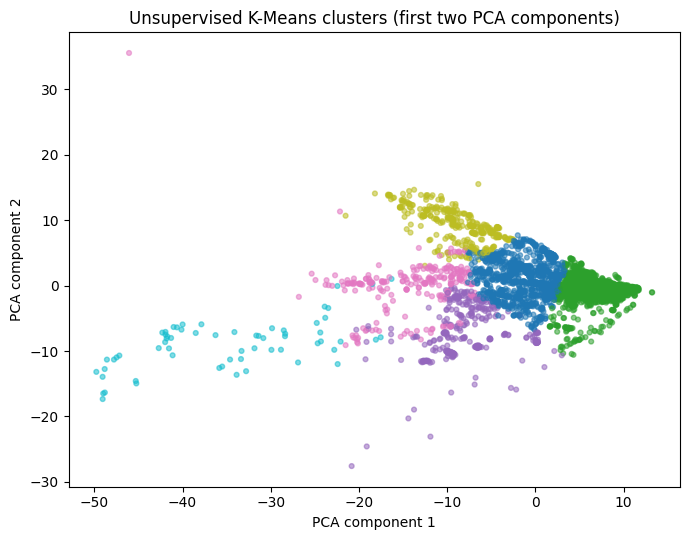

Cluster population:


,rows
cluster,
0,1135
1,1872
2,346
3,256
4,328
5,63


In [7]:
# Deterministic representative sample keeps clustering calculations practical.
cluster_sample = data.sample(n=min(4000, len(data)), random_state=SEED).copy()
X_cluster = StandardScaler().fit_transform(cluster_sample[feature_cols])
pca = PCA(n_components=10, random_state=SEED)
Z_cluster = pca.fit_transform(X_cluster)
kmeans = KMeans(n_clusters=6, n_init=10, random_state=SEED)
cluster_ids = kmeans.fit_predict(Z_cluster)
cluster_report = pd.DataFrame([{
    'sample_rows': len(cluster_sample), 'components_for_clustering': 10,
    'explained_variance_by_10_PCs': pca.explained_variance_ratio_.sum(),
    'silhouette_score': silhouette_score(Z_cluster, cluster_ids, sample_size=min(1200, len(Z_cluster)), random_state=SEED),
    'ARI_vs_gas_label (post-hoc)': adjusted_rand_score(cluster_sample['gas_id'], cluster_ids)
}])
display(cluster_report.round(4))
# Plot the first two PCA components, colored by unsupervised cluster IDs.
fig, ax = plt.subplots(figsize=(7, 5.5))
sc = ax.scatter(Z_cluster[:,0], Z_cluster[:,1], c=cluster_ids, s=12, alpha=.55, cmap='tab10')
ax.set_xlabel('PCA component 1'); ax.set_ylabel('PCA component 2')
ax.set_title('Unsupervised K-Means clusters (first two PCA components)')
plt.tight_layout(); plt.show()

print('Cluster population:')
display(pd.Series(cluster_ids).value_counts().sort_index().rename_axis('cluster').to_frame('rows'))

## 5. Conclusions template and research limitations

When writing the report, answer these with the results above:

1. Which validation model had the highest macro-F1? Did that same model generalize to batch 10?
2. Which gases were confused most often in the final confusion matrix? Suggest a sensor-response explanation, but do not claim causality from this analysis alone.
3. Did concentration regression outperform the median baseline in MAE/RMSE and R²? Which concentration ranges were hardest?
4. Does the clustering result suggest clear gas separation, partial grouping, or mostly overlapping patterns?
5. What are the limitations of a single later-batch holdout, derived sensor features, class/concentration imbalance across historical batches, and no external laboratory validation?

### CRISP-DM mapping
- **Business understanding:** reliable gas identification and concentration estimates despite drift.
- **Data understanding:** sensor features, gas labels, concentration and acquisition batches.
- **Data preparation:** parse indexed features and preserve batch provenance.
- **Modelling:** classification, transformed-target regression, PCA/K-Means.
- **Evaluation:** random in-period validation versus held-out later batch; MAE/RMSE/R²; clustering metrics.
- **Deployment planning:** require further calibration, drift monitoring, uncertainty analysis and independent sensor data before any real monitoring use.

### Syllabus mapping
- Data exploration and visualization; Logistic Regression; Decision Tree; KNN; SVM; regression metrics; clustering and interpretation.
- MNIST perceptron/MLP experiments are a separate required lab exercise and are not replaced by this dataset.